## **Обучение моделей.**

### **Линейная регрессия.**

Например,

$$
\text{удовлетворённость жизнью} = \theta_0 + \theta_1 * \text{ВВП на душу населения}
$$

это линейная функция от входного признака $\text{ВВП на душу населения}$. $\theta_0$ и $\theta_1$ - параметры модели. Такая модель вырабатывает прогноз, вычисляя взвешенную сумму входных признаков плюс константы под названием *член смещения* (*свободный член*).

#### Прогноз линейной регрессионной модели

$$
\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n
$$

- $\hat{y}$ - спрогнозированное решение.
- $n$ - количество признаков.
- $x_i$ - значение $i$-того признака.
- $\theta_j$ - $j$-тый параметр модели (включая член смещения $\theta_0$ и веса признаков $\theta_1$, $\theta_2$, ..., $\theta_n$).

#### Прогноз линейной регрессионной модели (векторизованная форма)

$$
\hat{y} = h_\theta (x) = \theta^T * x
$$

- $\theta$ - вектор параметров модели, содержащий член смещения $\theta_0$ и веса признаков от $\theta_1$ до $\theta_n$.
- $\theta^T$ - транспонированный $\theta$ (вектор-строка вместо вектора-столбца).
- $x$ - вектор признаков образца, содержащий от $x_0$ до $x_n$, где $x_0$ всегда равно 1.
- $h_\theta (x)$ - скалярное произведение $\theta^T$ и $x$.
- $h_\theta$ - функция гипотезы, использующая параметры модели $\theta$.

#### Функция издержек MSE для линейной регрессионной модели

$$
MSE(X, h_\theta) = \frac{1}{m} \sum_{i=1}^{m} (\theta^T * x^{(i)} - y^{(i)})^2
$$

### **Нормальное уравнение.**

### Нормальное уравнение

$$
\hat{\theta} = (X^T * X)^{-1} * X^T * y
$$

- $\hat{\theta}$ - значение $\theta$, которое сводит к минимуму функцию издержек.
- $y$ - вектор целевых значений, содержащий от $y^{(1)}$ до $y^{(m)}$.

*Сгенерируем псевдо линейные данные.*

In [2]:
import numpy as np

In [3]:
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.rand(100, 1)

In [6]:
import matplotlib.pyplot as plt

Text(0.5, 0, 'y')

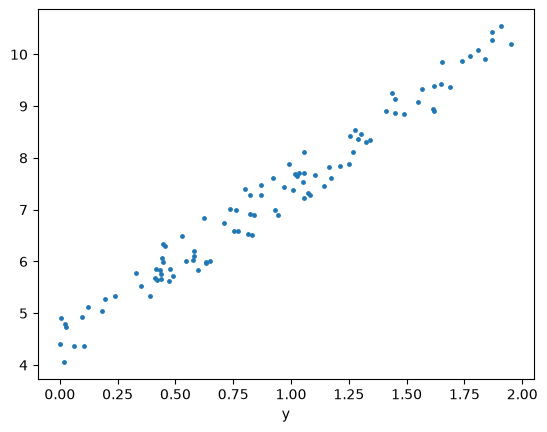

In [12]:
plt.scatter(X, y, s=6)
plt.xlabel("x1")
plt.xlabel("y")

*Вычислим $\theta$ с применением нормального кравнения.*

- `inv()` - получение обратной матрицы;
- `dot()` - умножение матриц.

In [14]:
X_b = np.c_[np.ones((100, 1)), X]
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
theta_best

array([[4.47062433],
       [3.01111456]])

Изначально было: $y = 4 + 3x_1 + \text{гауссов шум}$. *Мы получили близкие значения.*

*Теперь выработаем прогнозы, используя $\hat{\theta}$.*

In [16]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]  # Добавляет x0 = 1 к каждому образцу

y_predict = X_new_b.dot(theta_best)
y_predict

array([[ 4.47062433],
       [10.49285346]])

*Посмотрим на прогнозы на графике.*

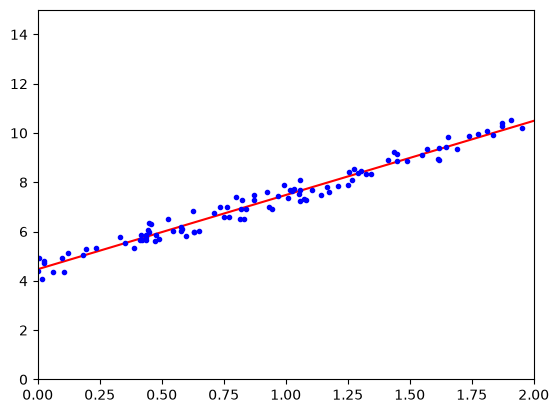

In [17]:
plt.plot(X_new, y_predict, "r-")
plt.plot(X, y, "b.")
plt.axis([0, 2, 0, 15])
plt.show()

*Эквивалентный код с использованием `Scikit-Learn`.*

In [18]:
from sklearn.linear_model import LinearRegression

In [19]:
lin_reg = LinearRegression()

In [20]:
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.01]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[4.47]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5.22]


In [21]:
lin_reg.intercept_, lin_reg.coef_

(array([4.47062433]), array([[3.01111456]]))

In [22]:
lin_reg.predict(X_new)

array([[ 4.47062433],
       [10.49285346]])

*Нормальное уравнение очень медленное в вычислительном плане с возрастанием количества признаков.*

### **Градиентный спуск.**

Для применения градиентного спуска нужно обеспечить у всех признаков похожего масштаба (например, с применением класса `StandartScaler` из `Scikit-Learn`), иначе времени на схождение потребуется намного больше.

### **Пакетный градиентный спуск.**

Нужно подсчитывать, насколько сильно функция издержек будет изменяться при небольшом изменении $\theta_j$. Результат - *частная производная*.

На каждой итерации используется **весь пакет** обучающих данных.

#### Частные производные функции издержек

$$
\frac{\partial}{\partial \theta_j} MSE(\theta) = \frac{2}{m} \sum_{i=1}^{m} (\theta^T * x^{(i)} - y^{(i)}) x_j^{(i)}
$$

Чтобы не вычислять все частные производные по отдельности можно вычислить *вектор-градиент*, который содержит все частные производные функции издержек (по одной для каждого параметра модели).

#### Вектор-градиент функции издержек

$$
\nabla_\theta MSE(\theta) = \begin{vmatrix} \frac{\partial}{\partial \theta_0} MSE(\theta) \\ \frac{\partial}{\partial \theta_1} MSE(\theta) \\ ... \\ \frac{\partial}{\partial \theta_n} MSE(\theta) \end{vmatrix} = \frac{2}{m} X^T * (X * \theta - y)
$$

Имея вектор-градиент, который указывает вверх, просто двигаемся в противоположном направлении вниз - вычитание $\nabla_\theta MSE(\theta)$ из $\theta$. Тут появляется $\eta$ - скорость обучения.

$$
\theta^\text{(следующий шаг)} = 0 - \eta \nabla_\theta MSE(\theta)
$$

- $\eta \nabla_\theta MSE(\theta)$ - размер шага.

In [24]:
eta = 0.1  # Скорость обучения
n_iterations = 1000
m = 100

theta = np.random.rand(2, 1)  # Случайная инициализация

for iteration in range(n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients

theta

array([[4.47062433],
       [3.01111456]])

*Посмотрим на результаты с разными значениями скорости обучения.*

In [29]:
etas = [0.00002, 0.1, 0.7]
n_iterations = 1000
m = 100

theta = np.random.rand(2, 1)  # Случайная инициализация
results_theta = []

for eta in etas:
    for iteration in range(n_iterations):
        gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
        theta = theta - eta * gradients
    results_theta.append(theta)

results_theta

[array([[0.52207902],
        [0.42190566]]),
 array([[4.47062433],
        [3.01111456]]),
 array([[-2.10026130e+223],
        [-2.21085408e+223]])]

### **Стохастический градиентный спуск.**

In [31]:
n_epochs = 50
t0, t1 = 5, 50

def learning_schedule(t):
    return t0 / (t + t1)

theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
    for i in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        gradients = 2 * xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients

theta

NameError: name 'yi' is not defined

In [32]:
from sklearn.linear_model import SGDRegressor

In [34]:
sgd_reg = SGDRegressor(n_iter_no_change=50, penalty=None, eta0=0.1)  # penalty=None - без регуляризации

In [36]:
sgd_reg.fit(X, y.ravel())

,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",None
,"eta0 eta0: float, default=0.01The initial learning rate for the 'constant', 'invscaling' or'adaptive' schedules. The default value is 0.01.Values must be in the range `(0.0, inf)`.For PA-1 (`learning_rate=pa1`) and PA-II (`pa2`), it specifies theaggressiveness parameter for the passive-aggressive algorithm, see [1] where itis called C:- For PA-I it is the maximum step size.- For PA-II it regularizes the step size (the smaller `eta0` the more it regularizes).As a general rule-of-thumb for PA, `eta0` should be small when the data isnoisy.",0.1
,"n_iter_no_change n_iter_no_change: int, default=5Number of iterations with no improvement to wait before stoppingfitting.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Integer values must be in the range `[1, max_iter)`... versionadded:: 0.20 Added 'n_iter_no_change' option",50
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0


In [37]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.45462795]), array([2.9937459]))